# Temporal prediction demo: synthetic teaching data

**Important scientific boundary:** this is a browser-runnable software demonstration, not a reproduction of the `kp-convergence-prediction` research analysis. The CSV is wholly synthetic: no real isolates, sequences, measured phenotypes, or study outputs are included. The outcome is an invented illustrative label, not a biological definition. Any metrics computed below apply only to these toy rows and are not be reported as evidence about *Klebsiella pneumoniae*.

To run this demo, just click on Run all (or run cells top to bottom).

This uses a simple logistic-regression baseline to demonstrate chronological evaluation concepts. It does **not** run HyperTraPS-CT, genome annotation, plasmid analysis, or the repository's full research pipeline.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path("toy_genomes_synthetic.csv")
# Raw GitHub URL to the synthetic file (edit the path to match where it lives in your repo)
URL = "https://raw.githubusercontent.com/Sourcify-y/kp-convergence-prediction/main/demo/toy_genomes_synthetic.csv"

df = pd.read_csv(DATA_PATH) if DATA_PATH.exists() else pd.read_csv(URL)
print(f"Loaded {len(df)} synthetic rows; {df.shape[1]} columns.")
display(df.head())


Loaded 16 synthetic rows; 7 columns.


,sample_id,collection_year,lineage_id,resistance_class_count,virulence_marker_count,shared_context_observed,illustrative_convergence_label
0,SYN001,2018,ST-A,1,1,0,0
1,SYN002,2018,ST-B,2,1,0,0
2,SYN003,2019,ST-C,1,2,0,0
3,SYN004,2019,ST-D,2,2,1,0
4,SYN005,2019,ST-E,3,1,0,0


## 1. Schema and missingness checks

In [ ]:
required = {
    "sample_id", "collection_year", "lineage_id",
    "resistance_class_count", "virulence_marker_count",
    "shared_context_observed", "illustrative_convergence_label"
}
assert required.issubset(df.columns), f"Missing columns: {required - set(df.columns)}"
assert df.sample_id.is_unique, "Sample IDs must be unique."
assert df.collection_year.notna().all(), "Years are required for temporal splitting."
assert set(df.illustrative_convergence_label.dropna().unique()).issubset({0, 1})
assert set(df.shared_context_observed.dropna().unique()).issubset({0, 1})
display(df.isna().sum().rename("missing_count").to_frame())
print("Schema checks passed. These checks validate the toy file only.")


,missing_count
sample_id,0
collection_year,0
lineage_id,0
resistance_class_count,0
virulence_marker_count,0
shared_context_observed,0
illustrative_convergence_label,0


Schema checks passed. These checks validate the toy file only.


## 2. Inspect temporal coverage

,synthetic_rows
collection_year,
2018,2
2019,3
2020,3
2021,3
2022,3
2023,2


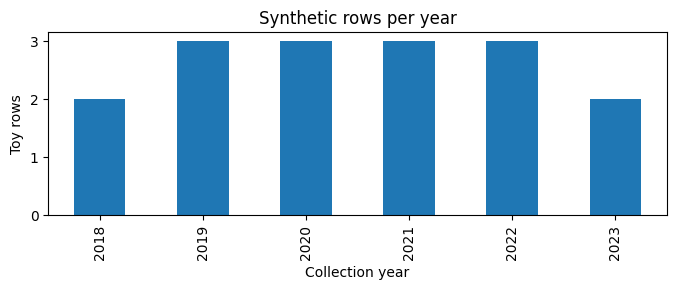

In [ ]:
year_counts = df.groupby("collection_year").size()
display(year_counts.rename("synthetic_rows").to_frame())
ax = year_counts.plot(kind="bar", figsize=(7, 3), title="Synthetic rows per year")
ax.set_xlabel("Collection year"); ax.set_ylabel("Toy rows")
plt.tight_layout(); plt.show()


## 3. Chronological split

The cutoff below is chosen only for this toy dataset: years through 2021 train the model, and 2022–2023 are held out. In real research, the cutoff and cohort rules should be fixed in the protocol before examining test performance. A time split alone does not guarantee lineage-, geography-, or outbreak-independent evaluation.


In [ ]:
FEATURES = ["resistance_class_count", "virulence_marker_count", "shared_context_observed"]
TARGET = "illustrative_convergence_label"
CUTOFF_YEAR = 2021
train = df[df.collection_year <= CUTOFF_YEAR].copy()
test = df[df.collection_year > CUTOFF_YEAR].copy()
assert not train.empty and not test.empty
assert train[TARGET].nunique() == 2, "Training data must contain both toy labels."
print(f"Train: {len(train)} rows; years {train.collection_year.min()}–{train.collection_year.max()}")
print(f"Test: {len(test)} rows; years {test.collection_year.min()}–{test.collection_year.max()}")
print("Training label counts:", train[TARGET].value_counts().sort_index().to_dict())
print("Test label counts:", test[TARGET].value_counts().sort_index().to_dict())


Train: 11 rows; years 2018–2021
Test: 5 rows; years 2022–2023
Training label counts: {0: 8, 1: 3}
Test label counts: {0: 2, 1: 3}


## 4. Fit and evaluate a simple baseline

Preprocessing is fitted on training data only. Results generated by this cell are toy-data outputs, not research findings.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

model = make_pipeline(StandardScaler(), LogisticRegression(random_state=0, max_iter=1000))
model.fit(train[FEATURES], train[TARGET])
pred = model.predict(test[FEATURES])
prob = model.predict_proba(test[FEATURES])[:, 1]
metrics = pd.DataFrame([{
    "scope": "synthetic toy data only",
    "n_train": len(train), "n_test": len(test),
    "accuracy": accuracy_score(test[TARGET], pred),
    "balanced_accuracy": balanced_accuracy_score(test[TARGET], pred),
    "precision": precision_score(test[TARGET], pred, zero_division=0),
    "recall": recall_score(test[TARGET], pred, zero_division=0),
    "f1": f1_score(test[TARGET], pred, zero_division=0)
}])
display(metrics.round(3))
print(classification_report(test[TARGET], pred, zero_division=0))


,scope,n_train,n_test,accuracy,balanced_accuracy,precision,recall,f1
0,synthetic toy data only,11,5,1.0,1.0,1.0,1.0,1.0


              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



## 5. Inspect held-out toy predictions

,sample_id,collection_year,lineage_id,illustrative_convergence_label,predicted_toy_label,predicted_toy_probability
11,SYN012,2022,ST-L,1,1,0.845904
12,SYN013,2022,ST-M,1,1,0.818102
13,SYN014,2022,ST-N,0,0,0.284145
14,SYN015,2023,ST-O,1,1,0.920077
15,SYN016,2023,ST-P,0,0,0.112733


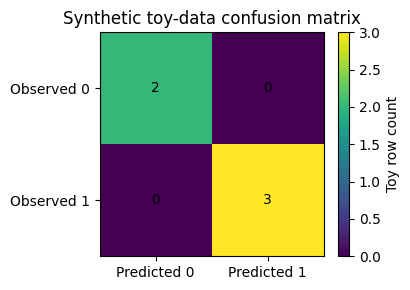

In [ ]:
held_out = test[["sample_id", "collection_year", "lineage_id", TARGET]].copy()
held_out["predicted_toy_label"] = pred
held_out["predicted_toy_probability"] = prob
display(held_out)

cm = confusion_matrix(test[TARGET], pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(4, 3))
im = ax.imshow(cm)
ax.set_xticks([0, 1], labels=["Predicted 0", "Predicted 1"])
ax.set_yticks([0, 1], labels=["Observed 0", "Observed 1"])
ax.set_title("Synthetic toy-data confusion matrix")
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha="center", va="center")
fig.colorbar(im, ax=ax, label="Toy row count")
plt.tight_layout()
plt.show()


## 6. Interpretation boundary

This notebook demonstrates file loading, basic validation, a chronological holdout, training-only preprocessing, and metric reporting. It does **not** establish genomic prediction, causal effects, plasmid transfer, same-contig linkage, or generalization to unseen lineages. It does not execute HyperTraPS-CT or reproduce the study's 8,318-genome analysis.


